# ML Lab-6
## Name: Amey Shendre
## Batch: A-A2
## Roll no: 26

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("seeds_new (1).csv")
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [2]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3,NaN,NaN
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3,NaN,NaN
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3,NaN,NaN
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3,NaN,NaN
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3,NaN,NaN


In [3]:
df.shape

(210, 10)

In [4]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)', 'Unnamed: 8', 'Unnamed: 9'],
      dtype='object')

In [5]:
df.dtypes

,0
Area,float64
Perimeter,float64
Compactness,float64
Length of kernel,float64
Width of kernel,float64
Asymmetry coefficient,float64
Length of kernel groove,float64
"Class (1, 2, 3)",int64
Unnamed: 8,object
Unnamed: 9,object


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
 8   Unnamed: 8               2 non-null      object 
 9   Unnamed: 9               1 non-null      object 
dtypes: float64(7), int64(1), object(2)
memory usage: 16.5+ KB


In [7]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [8]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0
Unnamed: 8,208
Unnamed: 9,209


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
# Remove completely empty columns from the dataset
empty_columns = df.columns[df.isnull().all()]
print("Completely empty columns:", list(empty_columns))

df = df.drop(columns=empty_columns)

print("Shape after removing empty columns:", df.shape)
df.head()

Completely empty columns: []
Shape after removing empty columns: (210, 10)


,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [11]:
# Check for zero values in numeric feature columns
feature_columns = [
    "Area", "Perimeter", "Compactness", "Length of kernel",
    "Width of kernel", "Asymmetry coefficient", "Length of kernel groove"
]

zero_counts = (df[feature_columns] == 0).sum()
print("Zero Values:")
print(zero_counts)

Zero Values:
Area                       0
Perimeter                  0
Compactness                0
Length of kernel           0
Width of kernel            0
Asymmetry coefficient      0
Length of kernel groove    0
dtype: int64


In [12]:
# 1. Plot the box-plot
# 2. Plot the histogram
# 3. Pie chart (classes)
# 4. Scatterplot
# 5. Heatmap
# 6. Pairplot

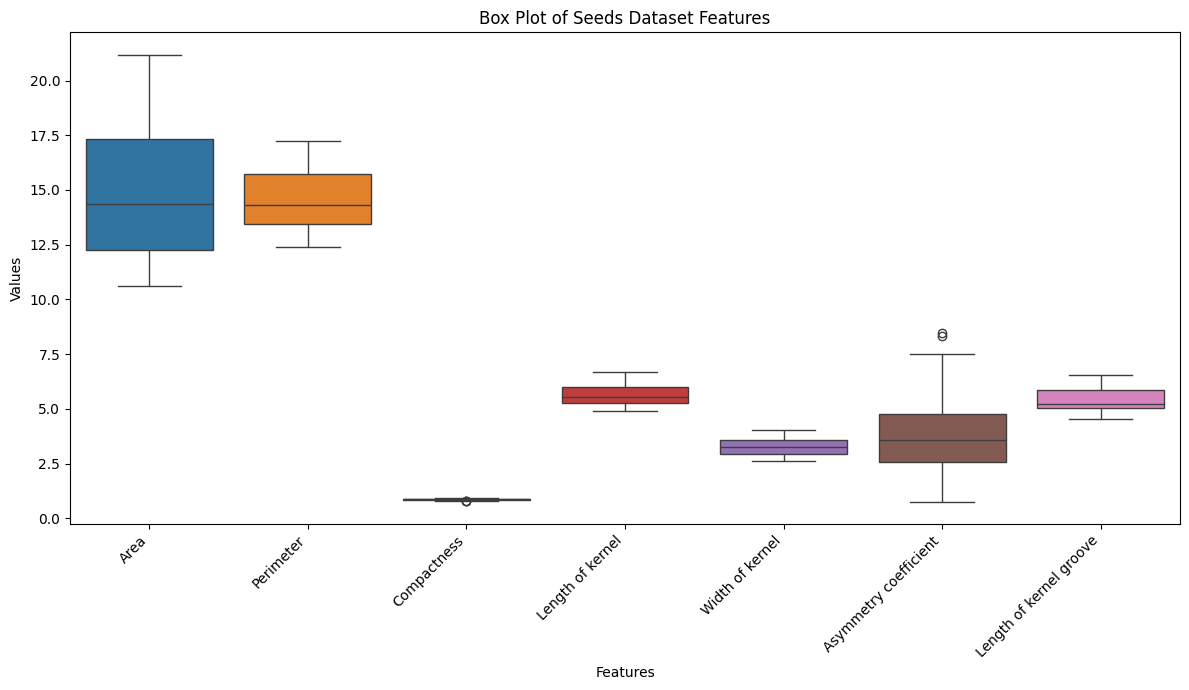

In [13]:
# 1. Box Plot
plt.figure(figsize=(12, 7))
sns.boxplot(data=df[feature_columns])
plt.xlabel("Features")
plt.ylabel("Values")
plt.title("Box Plot of Seeds Dataset Features")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

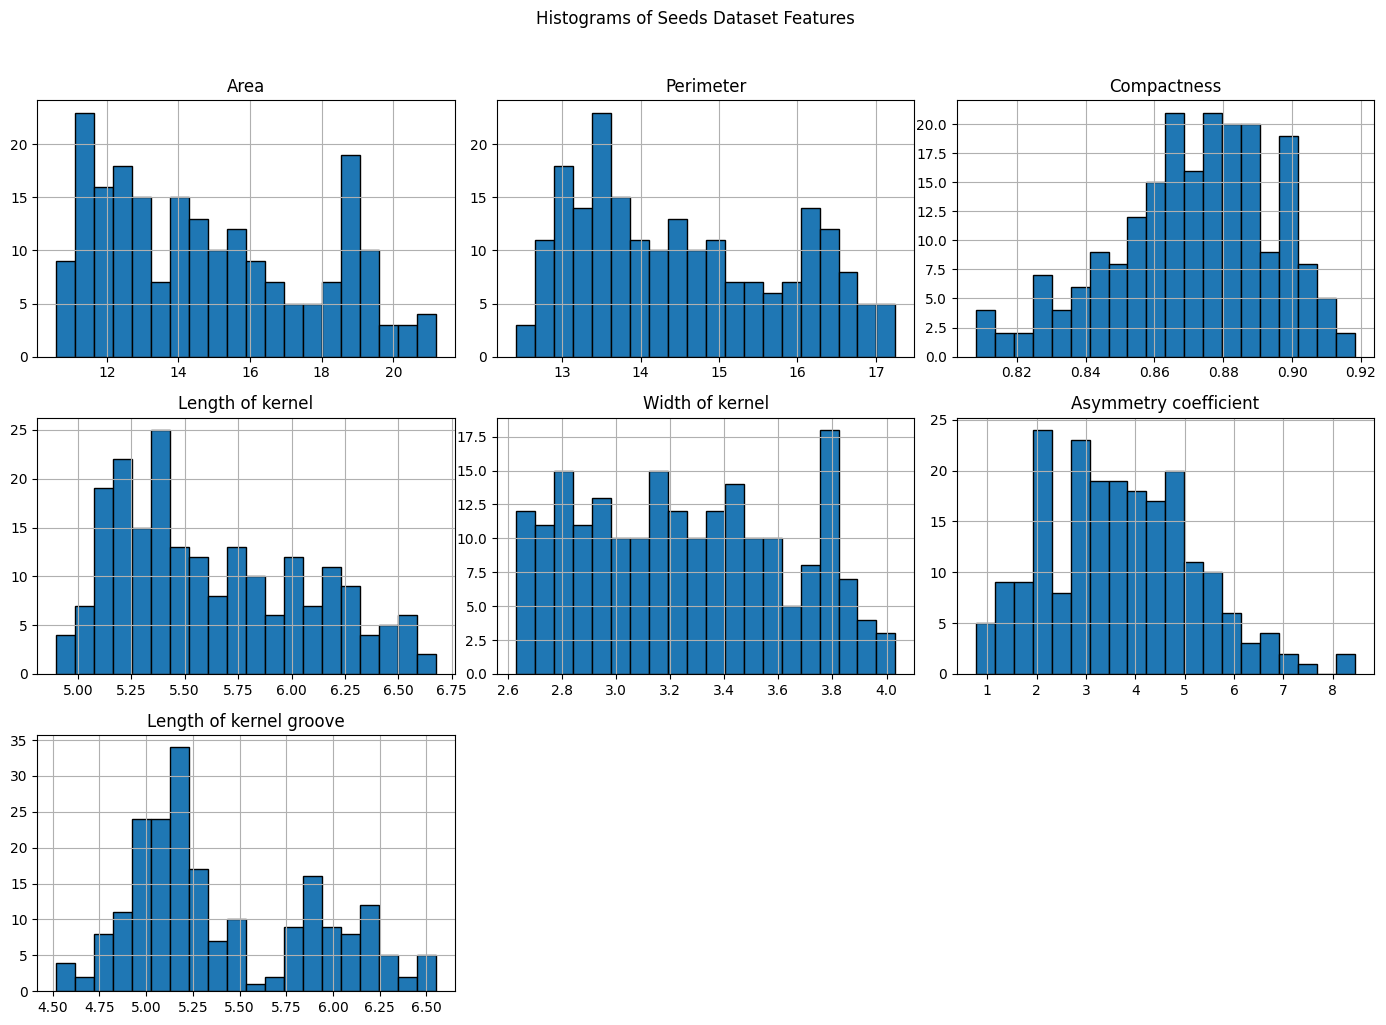

In [14]:
# 2. Histograms
df[feature_columns].hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Histograms of Seeds Dataset Features", y=1.02)
plt.tight_layout()
plt.show()

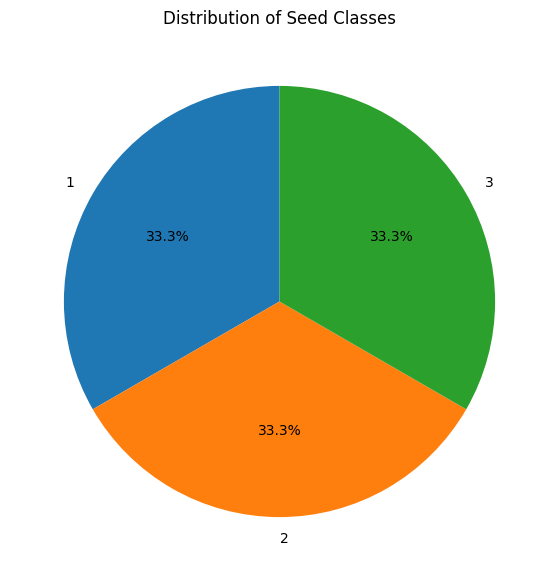

Class Counts:
Class (1, 2, 3)
1    70
2    70
3    70
Name: count, dtype: int64


In [15]:
# 3. Pie Chart - Class Distribution
class_counts = df["Class (1, 2, 3)"].value_counts().sort_index()

plt.figure(figsize=(7, 7))
plt.pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Distribution of Seed Classes")
plt.show()

print("Class Counts:")
print(class_counts)

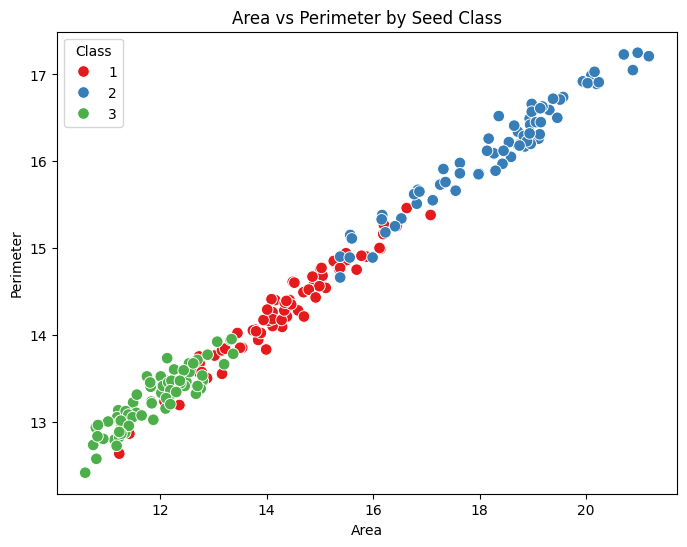

In [16]:
# 4. Scatter Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Area",
    y="Perimeter",
    hue="Class (1, 2, 3)",
    palette="Set1",
    s=70
)
plt.xlabel("Area")
plt.ylabel("Perimeter")
plt.title("Area vs Perimeter by Seed Class")
plt.legend(title="Class")
plt.show()

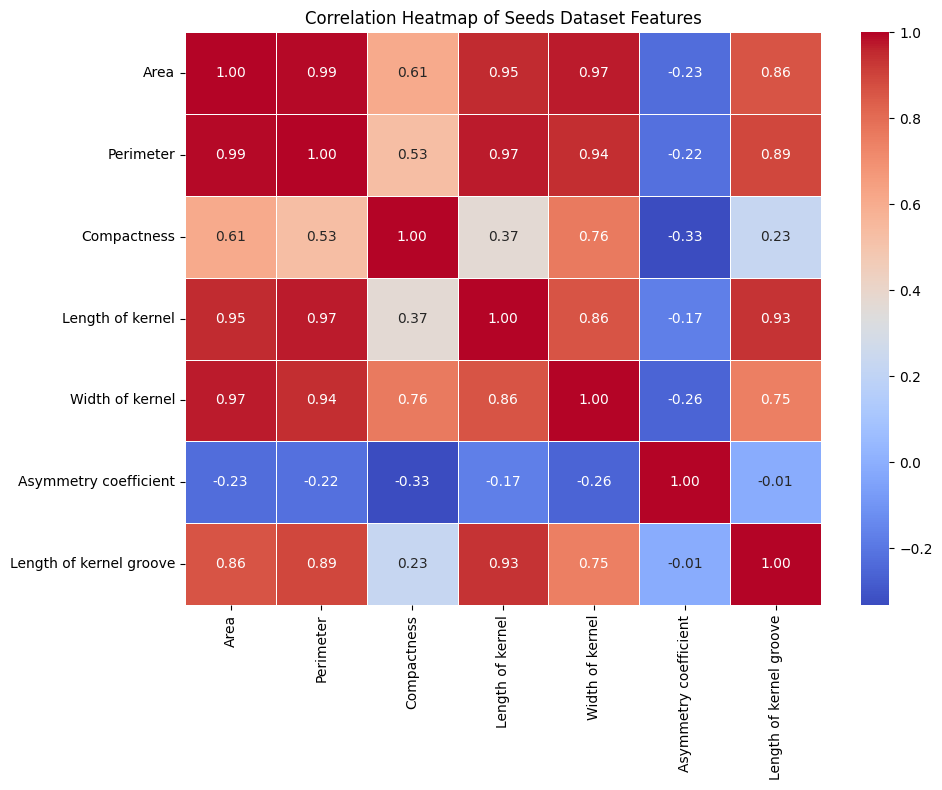

In [17]:
# 5. Heatmap - Correlation Matrix
correlation_matrix = df[feature_columns].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Seeds Dataset Features")
plt.tight_layout()
plt.show()

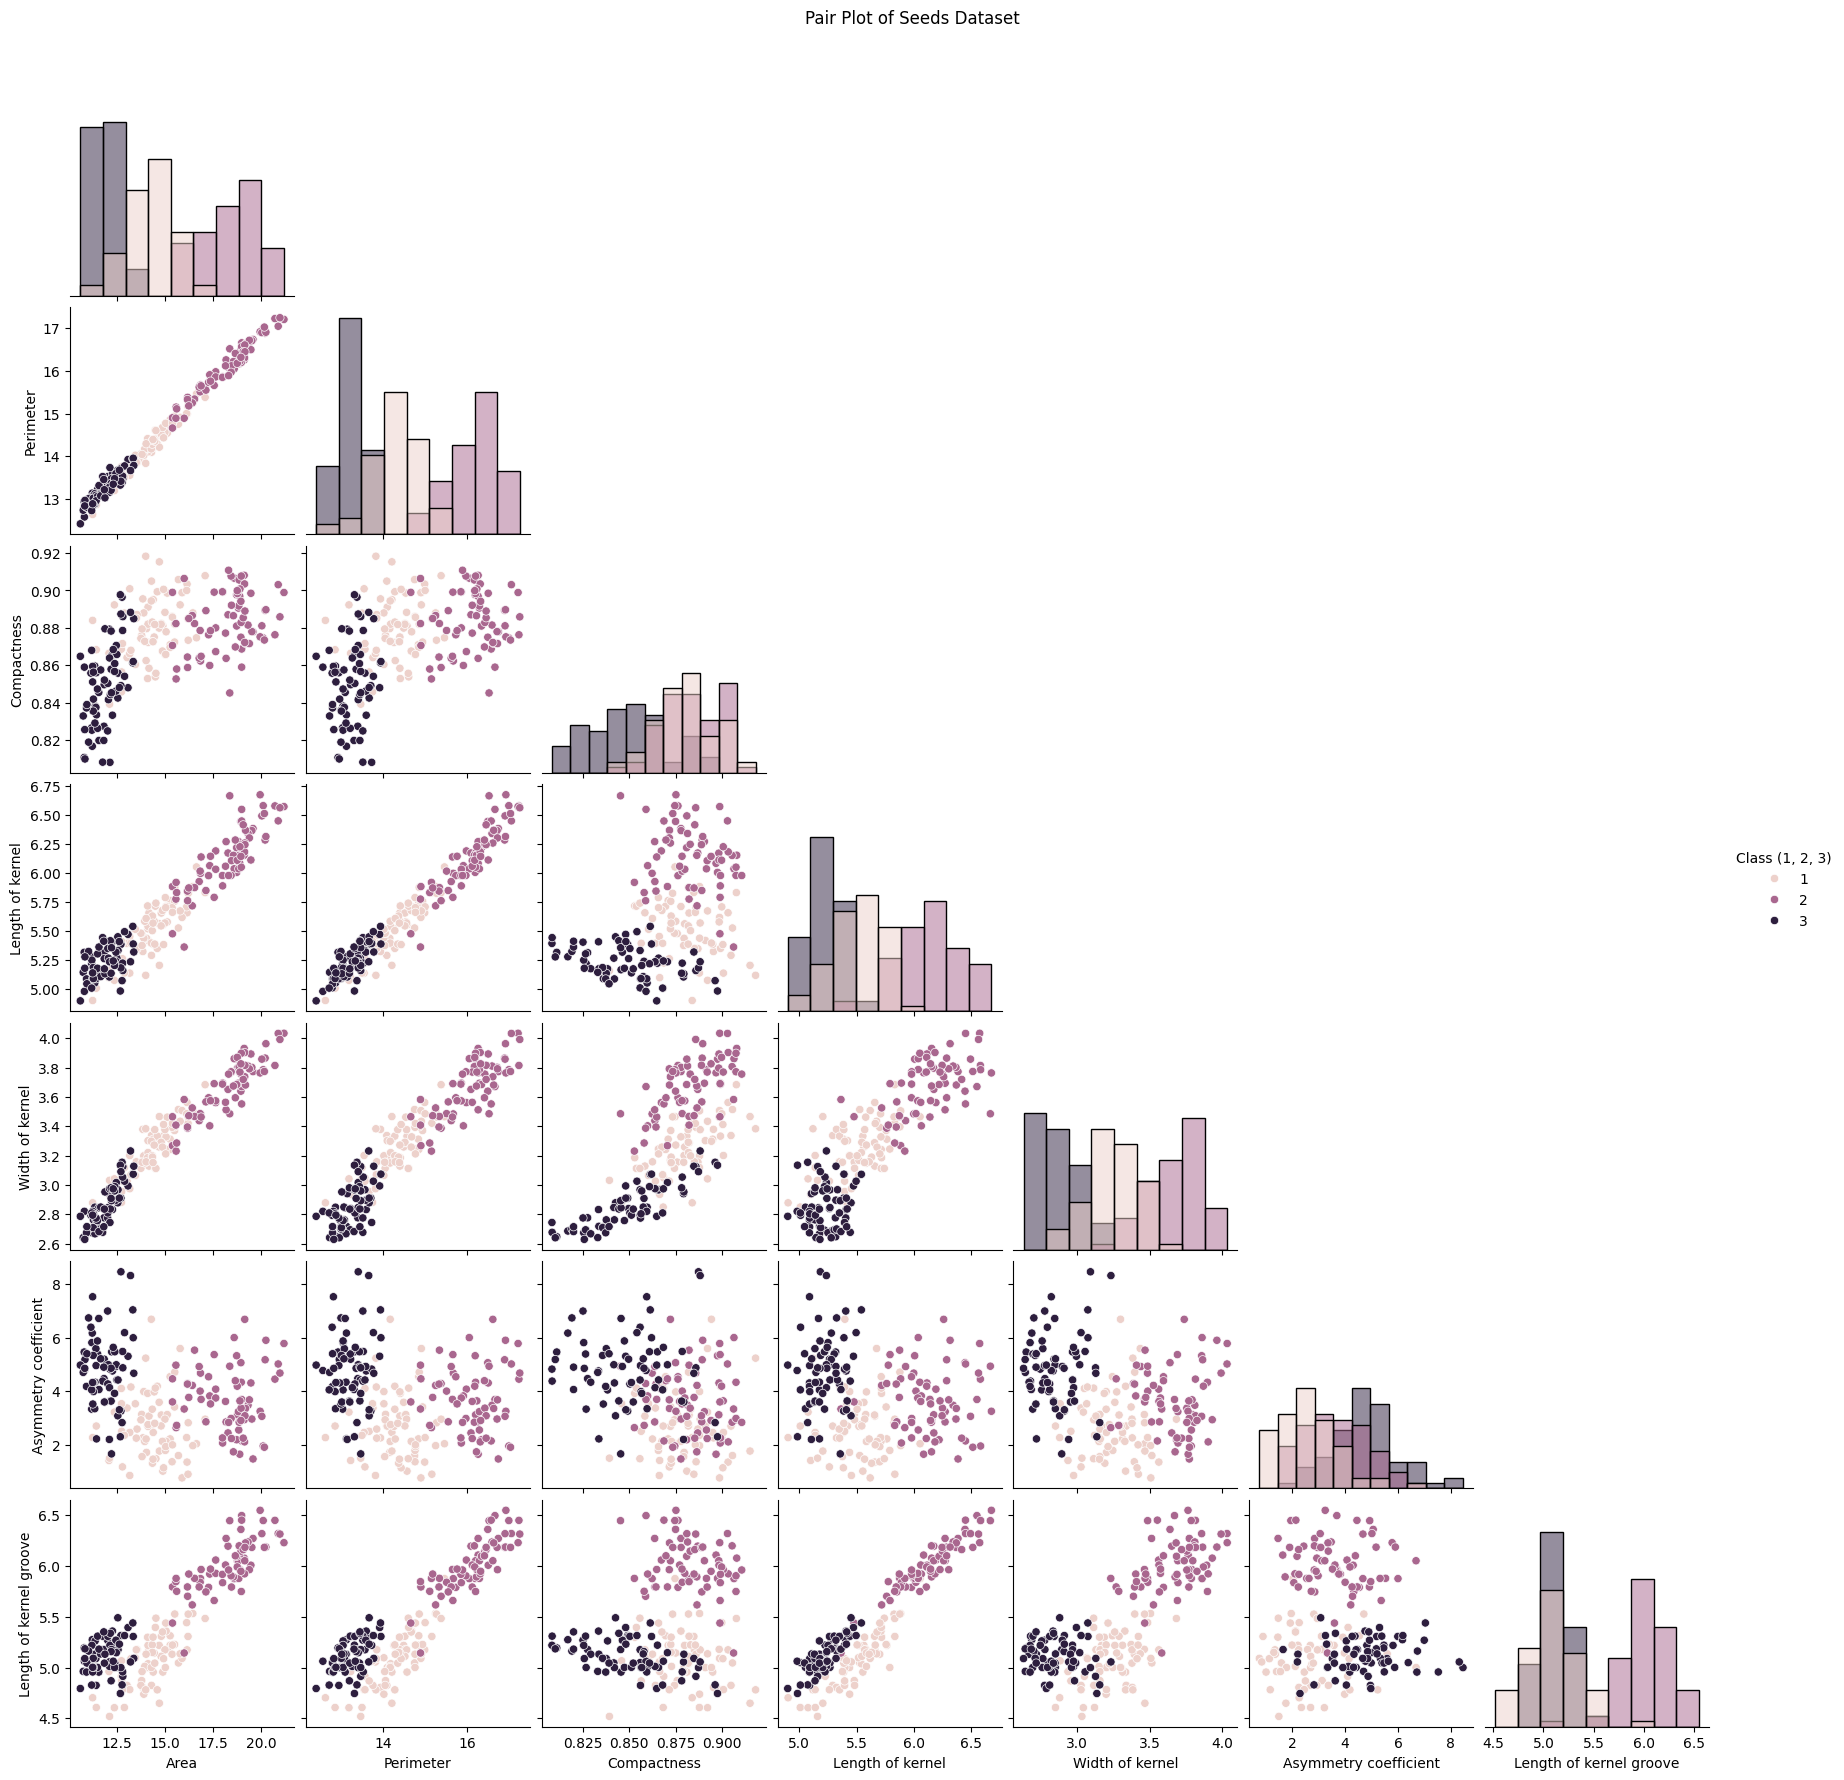

In [18]:
# 6. Pair Plot
sns.pairplot(
    df,
    vars=feature_columns,
    hue="Class (1, 2, 3)",
    diag_kind="hist",
    corner=True
)
plt.suptitle("Pair Plot of Seeds Dataset", y=1.02)
plt.show()

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ( accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)

In [20]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

In [21]:
X = df.drop("Class (1, 2, 3)", axis=1)
y_original = df["Class (1, 2, 3)"]

print("Input Shape:", X.shape)
print("Output Shape:", y_original.shape)

Input Shape: (210, 9)
Output Shape: (210,)


In [22]:
y = y_original - 1
print("Original classes:")
print(sorted(y_original.unique()))

print("\nANN encoded classes:")
print(sorted(y.unique()))

Original classes:
[np.int64(1), np.int64(2), np.int64(3)]

ANN encoded classes:
[np.int64(0), np.int64(1), np.int64(2)]


In [23]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 168
Testing samples: 42


In [24]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [25]:
# Select only the 7 correct numeric feature columns to scale
X_train_clean = X_train[feature_columns]
X_test_clean = X_test[feature_columns]

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

In [26]:
model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(3, activation="softmax")
])

In [27]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
model.compile(optimizer=Adam(learning_rate=0.001),loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [29]:
loss = "sparse_categorical_corssentropy"

In [30]:
early_stop = EarlyStopping(monitor="val_loss",patience=10,restore_best_weights=True)

In [31]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.02,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.2073 - loss: 1.1720 - val_accuracy: 0.0000e+00 - val_loss: 1.1966
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.2317 - loss: 1.0971 - val_accuracy: 0.0000e+00 - val_loss: 1.0822
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.2805 - loss: 1.0378 - val_accuracy: 0.2500 - val_loss: 0.9892
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3476 - loss: 0.9899 - val_accuracy: 0.5000 - val_loss: 0.9122
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.4451 - loss: 0.9473 - val_accuracy: 0.7500 - val_loss: 0.8569
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5305 - loss: 0.9105 - val_accuracy: 0.7500 - val_loss: 0.7997
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5488 - loss: 0.8747 - val_accuracy: 0.7500 - val_loss: 0.7392
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.7012 - loss: 0.8345 - val_accu

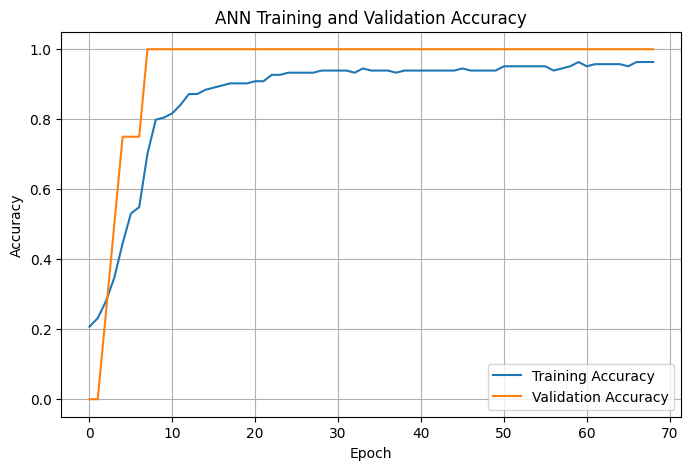

In [32]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")

plt.title("ANN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [33]:
test_loss, test_accuracy = model.evaluate(X_test_scaled,y_test, verbose=1)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8571 - loss: 0.2956
Test Loss: 0.29561343789100647
Test Accuracy: 0.8571428656578064


In [34]:
y_prob = model.predict(X_test_scaled,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
[[9.8337650e-01 8.3304439e-03 8.2929907e-03]
 [3.7455179e-02 4.9859514e-03 9.5755881e-01]
 [5.8462471e-01 4.0550485e-01 9.8703699e-03]
 [1.9152020e-03 5.8929145e-04 9.9749547e-01]
 [4.2636087e-03 9.9572033e-01 1.6162003e-05]]


In [35]:
y_pred = np.argmax(y_prob,axis=1)
print("Predicted encoded classes:")
print(y_pred[:10])

Predicted encoded classes:
[0 2 0 2 1 2 1 0 1 1]


In [36]:
y_pred_original = y_pred + 1
y_test_original = y_test + 1

print("Predicted classes:")
print(y_pred_original[:10])

Predicted classes:
[1 3 1 3 2 3 2 1 2 2]


In [37]:
comparision = pd.DataFrame({
    "Actual Class": y_test_original.values,
    "Predicted Class": y_pred_original
})
comparision.head(10)

,Actual Class,Predicted Class
0,1,1
1,3,3
2,2,1
3,3,3
4,2,2
5,3,3
6,2,2
7,1,1
8,2,2
9,2,2


In [38]:
accuracy = accuracy_score(y_test_original,y_pred_original)
print("Accuracy:", accuracy)

Accuracy: 0.8571428571428571


In [39]:
precision = precision_score(y_test_original,y_pred_original,average="weighted")
print("Precision:", precision)

Precision: 0.8633986928104576


In [40]:
recall = recall_score(y_test_original,y_pred_original,average="weighted")
print("Recall:", recall)

Recall: 0.8571428571428571


In [41]:
f1 = f1_score(y_test_original,y_pred_original,average="weighted")
print("F1 Score:", f1)

F1 Score: 0.849925843529848


In [42]:
metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Value": [accuracy, precision, recall, f1]
})
metrics

,Metric,Value
0,Accuracy,0.857143
1,Precision,0.863399
2,Recall,0.857143
3,F1 Score,0.849926


In [43]:
print(classification_report(y_test_original,y_pred_original))

              precision    recall  f1-score   support

           1       0.90      0.64      0.75        14
           2       0.87      0.93      0.90        14
           3       0.82      1.00      0.90        14

    accuracy                           0.86        42
   macro avg       0.86      0.86      0.85        42
weighted avg       0.86      0.86      0.85        42



In [44]:
cm = confusion_matrix(y_test_original,y_pred_original)
print(cm)

[[ 9  2  3]
 [ 1 13  0]
 [ 0  0 14]]


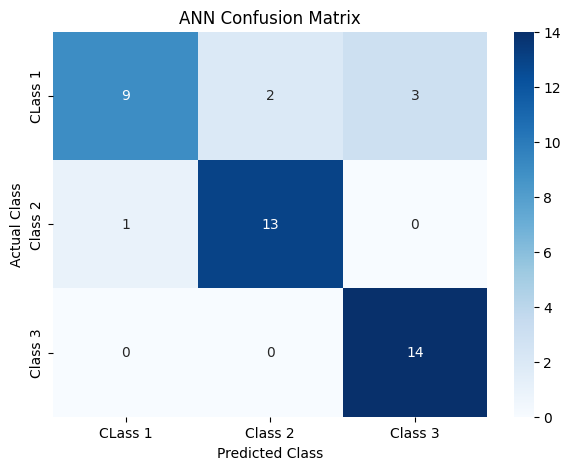

In [45]:
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",xticklabels=["CLass 1", "Class 2", "Class 3"], yticklabels=["CLass 1", "Class 2", "Class 3"])
plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

<Axes: >

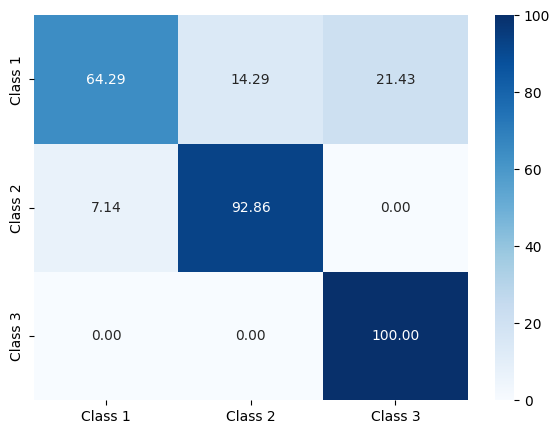

In [46]:
cm_percentage = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]*100
plt.figure(figsize=(7,5))
sns.heatmap(cm_percentage, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=["Class 1", "Class 2", "Class 3"],yticklabels=["Class 1", "Class 2", "Class 3"])

In [54]:
def predict_new_seed(area, perimeter, compactness, length, width, asymmetry, groove_length):
  new_sample = pd.DataFrame([
      [area, perimeter, compactness, length, width, asymmetry, groove_length]
  ], columns=feature_columns)

  new_sample_scaled = scaler.transform(new_sample)
  prediction = model.predict(new_sample_scaled)
  predicted_class = np.argmax(prediction, axis=1)[0] + 1
  print(f"\nPredicted Class: {predicted_class}")

area = float(input("Enter Area:"))
perimeter = float(input("Enter Perimeter:"))
compactness = float(input("Enter Compactness:"))
length = float(input("Enter Length of Kernel:"))
width = float(input("Enter Width of Kernel:"))
asymmetry = float(input("Enter Asymmetry Coefficient:"))
groove = float(input("Enter Length of Kernel Groove:"))

predict_new_seed(area, perimeter, compactness, length, width, asymmetry, groove)

Enter Area:10
Enter Perimeter:10
Enter Compactness:10
Enter Length of Kernel:10
Enter Width of Kernel:10
Enter Asymmetry Coefficient:10
Enter Length of Kernel Groove:10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step

Predicted Class: 2
